# Brazilian E-commerce Sales, Customer Behaviour and Churn Analysis

## 1. Project Overview

This project explores the Brazilian E-Commerce Public Dataset by Olist and includes a beginner-level customer churn classification experiment.

The notebook covers data loading, cleaning, exploratory analysis, product and customer behaviour, historical revenue trends, customer feature preparation, classification, and model evaluation.

The aim is to demonstrate a complete foundational data-analysis and machine-learning workflow while clearly reporting the limitations found in the dataset.



## 2. Business Problem

The objective of this project is to analyze e-commerce sales data and identify important business patterns.

The project focuses on:

- Understanding sales trends and revenue performance.
- Identifying top-performing product categories.
- Analyzing customer purchasing behaviour.
- Understanding customer inactivity and retention.
- Building and evaluating sales forecasting and churn prediction models.
- Providing data-driven business recommendations.



## 3. Dataset Description

This project uses the Brazilian E-Commerce Public Dataset by Olist, available on Kaggle.

**Dataset details:**
- Source: Olist Brazilian E-Commerce Dataset
- Format: CSV files
- Data includes customers, orders, products, sellers, payments, reviews, and geolocation.
- Currency: Brazilian Real (BRL).

**Main datasets used:**
- Customers
- Orders
- Order Items
- Payments
- Reviews
- Products
- Sellers
- Geolocation
- Product Category Translation

The datasets are connected using common identifiers such as `customer_id` and `order_id`.


In [1]:
import sys

print(sys.version)
print(sys.executable)

3.13.5 (main, Jul 15 2026, 20:25:40) [GCC 14.2.0]
/opt/pyvenv/bin/python



## 4. Importing Libraries

Import the required Python libraries for data manipulation, visualization, statistical analysis, and machine learning.

Libraries used in this project include:

- Pandas and NumPy for data manipulation.
- Matplotlib and Seaborn for data visualization.
- Scikit-learn for machine learning and model evaluation.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

print("All libraries imported successfully!")

Pandas: 2.2.3
NumPy: 2.3.5
Scikit-learn: 1.8.0
All libraries imported successfully!



## 5. Data Loading and Initial Exploration

Load the Olist CSV datasets using Pandas and perform an initial inspection to understand their structure.

The initial exploration includes:

- Checking dataset dimensions (rows and columns).
- Inspecting column names and data types.
- Checking missing values.
- Identifying duplicate records.
- Understanding the overall data structure.


In [3]:
import pandas as pd

customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")

orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")

reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")

products = pd.read_csv("../data/raw/olist_products_dataset.csv")

sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")

geolocation = pd.read_csv("../data/raw/olist_geolocation_dataset.csv")

category_translation = pd.read_csv("../data/raw/product_category_name_translation.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [4]:
datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Sellers": sellers,
    "Geolocation": geolocation,
    "Category Translation": category_translation
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Customers: (99441, 5)
Orders: (99441, 8)
Order Items: (112650, 7)
Payments: (103886, 5)
Reviews: (99224, 7)
Products: (32951, 9)
Sellers: (3095, 4)
Geolocation: (1000163, 5)
Category Translation: (71, 2)


In [5]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.columns.tolist())
    print("-" * 60)



Customers
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
------------------------------------------------------------

Orders
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
------------------------------------------------------------

Order Items
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
------------------------------------------------------------

Payments
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']
------------------------------------------------------------

Reviews
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']
------------------------------------------------------------

Products
[

In [6]:
import pandas as pd
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

In [7]:
customer_orders = orders.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

repeat_customers = customer_orders['customer_unique_id'].value_counts()
repeat_customers = repeat_customers[repeat_customers > 1]

print(repeat_customers)

customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    17
3e43e6105506432c953e165fb2acf44c     9
ca77025e7201e3b30c44b472ff346268     7
1b6c7548a2a1f9037c1fd3ddfed95f33     7
6469f99c1f9dfae7733b25662e7f1782     7
                                    ..
5ee1a7e84a17bcddc784977557a7a186     2
ee86c319ba988c50816cb59a863b1882     2
9f67aa18a87ea9a76854deeb9385c011     2
d1085381045ea6f88be5cc3e14c61e55     2
ae8482b27b2119e2c3278f5ddf9c1024     2
Name: count, Length: 2997, dtype: int64


In [8]:
len(repeat_customers)

2997

In [9]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [10]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [11]:
print(customers.isnull().sum())
print(orders.isnull().sum())

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [12]:
print(orders['order_status'].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [13]:
print("Duplicate orders:", orders['order_id'].duplicated().sum())
print("Duplicate customers:", customers['customer_id'].duplicated().sum())

Duplicate orders: 0
Duplicate customers: 0


In [14]:
orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

In [15]:
print(orders['order_purchase_timestamp'].dtype)

datetime64[ns]


In [16]:
orders['year'] = orders['order_purchase_timestamp'].dt.year
orders['month'] = orders['order_purchase_timestamp'].dt.month

print(orders[['order_purchase_timestamp', 'year', 'month']].head())

  order_purchase_timestamp  year  month
0      2017-10-02 10:56:33  2017     10
1      2018-07-24 20:41:37  2018      7
2      2018-08-08 08:38:49  2018      8
3      2017-11-18 19:28:06  2017     11
4      2018-02-13 21:18:39  2018      2


In [17]:
orders['month_name'] = orders['order_purchase_timestamp'].dt.month_name()

print(orders[['year', 'month', 'month_name']].head())

   year  month month_name
0  2017     10    October
1  2018      7       July
2  2018      8     August
3  2017     11   November
4  2018      2   February


In [18]:
print("First order:", orders['order_purchase_timestamp'].min())
print("Last order:", orders['order_purchase_timestamp'].max())

First order: 2016-09-04 21:15:19
Last order: 2018-10-17 17:30:18


In [19]:
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")
reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")
products = pd.read_csv("../data/raw/olist_products_dataset.csv")
sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")
geolocation = pd.read_csv("../data/raw/olist_geolocation_dataset.csv")
category_translation = pd.read_csv("../data/raw/product_category_name_translation.csv")

In [20]:
datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Sellers": sellers,
    "Geolocation": geolocation,
    "Category Translation": category_translation
}


## 6. Data Cleaning and Preparation

Clean and prepare the raw datasets to ensure data quality and consistency before performing further analysis.

The cleaning process includes:

- Handling missing values.
- Checking and removing duplicate records where appropriate.
- Converting date columns into datetime format.
- Filtering delivered orders for completed-sales analysis.
- Joining relevant datasets using common identifiers.
- Calculating product revenue and freight charges.
- Creating the cleaned delivered sales dataset.


In [21]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.isnull().sum()[df.isnull().sum() > 0])
    


Customers
Series([], dtype: int64)

Orders
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Order Items
Series([], dtype: int64)

Payments
Series([], dtype: int64)

Reviews
review_comment_title      87656
review_comment_message    58247
dtype: int64

Products
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Sellers
Series([], dtype: int64)

Geolocation


Series([], dtype: int64)

Category Translation
Series([], dtype: int64)


In [22]:
for name, df in datasets.items():
    missing_percent = (df.isnull().sum() / len(df)) * 100
    missing_percent = missing_percent[missing_percent > 0]

    if not missing_percent.empty:
        print(f"\n{name}")
        print(missing_percent.round(2))


Orders
order_approved_at                0.16
order_delivered_carrier_date     1.79
order_delivered_customer_date    2.98
dtype: float64

Reviews
review_comment_title      88.34
review_comment_message    58.70
dtype: float64

Products
product_category_name         1.85
product_name_lenght           1.85
product_description_lenght    1.85
product_photos_qty            1.85
product_weight_g              0.01
product_length_cm             0.01
product_height_cm             0.01
product_width_cm              0.01
dtype: float64


In [23]:
total_revenue = order_items['price'].sum()

print("Total Product Revenue:", total_revenue)

Total Product Revenue: 13591643.7


In [24]:
total_freight = order_items['freight_value'].sum()

print("Total Freight:", total_freight)

Total Freight: 2251909.54


In [25]:
order_revenue = (
    order_items.groupby('order_id')
    .agg(
        product_revenue=('price', 'sum'),
        total_freight=('freight_value', 'sum')
    )
    .reset_index()
)

order_revenue['total_revenue'] = (
    order_revenue['product_revenue'] +
    order_revenue['total_freight']
)

print(order_revenue.head())


                           order_id  ...  total_revenue
0  00010242fe8c5a6d1ba2dd792cb16214  ...          72.19
1  00018f77f2f0320c557190d7a144bdd3  ...         259.83
2  000229ec398224ef6ca0657da4fc703e  ...         216.87
3  00024acbcdf0a6daa1e931b038114c75  ...          25.78
4  00042b26cf59d7ce69dfabb4e55b4fd9  ...         218.04

[5 rows x 4 columns]


In [26]:
order_revenue = (
    order_items.groupby('order_id')
    .agg(
        product_revenue = ('price', 'sum'),
        total_freight = ('freight_value', 'sum')
    )
    .reset_index()
)
order_revenue['total_revenue'] = (
    order_revenue['product_revenue'] +
    order_revenue['total_freight']
)

print(order_revenue.head())

                           order_id  ...  total_revenue
0  00010242fe8c5a6d1ba2dd792cb16214  ...          72.19
1  00018f77f2f0320c557190d7a144bdd3  ...         259.83
2  000229ec398224ef6ca0657da4fc703e  ...         216.87
3  00024acbcdf0a6daa1e931b038114c75  ...          25.78
4  00042b26cf59d7ce69dfabb4e55b4fd9  ...         218.04

[5 rows x 4 columns]


In [27]:
sales_data = orders [
    [
    'order_id',
    'customer_id',
    'order_status',
    'order_purchase_timestamp'
    ]
].merge(
    order_revenue,
    on='order_id',
    how='left'
)

print(sales_data.head())

                           order_id  ... total_revenue
0  e481f51cbdc54678b7cc49136f2d6af7  ...         38.71
1  53cdb2fc8bc7dce0b6741e2150273451  ...        141.46
2  47770eb9100c2d0c44946d9cf07ec65d  ...        179.12
3  949d5b44dbf5de918fe9c16f97b45f8a  ...         72.20
4  ad21c59c0840e6cb83a9ceb5573f8159  ...         28.62

[5 rows x 7 columns]


In [28]:
print(sales_data.shape)

print(sales_data.isnull().sum())

print(sales_data.head())

(99441, 7)
order_id                      0
customer_id                   0
order_status                  0
order_purchase_timestamp      0
product_revenue             775
total_freight               775
total_revenue               775
dtype: int64
                           order_id  ... total_revenue
0  e481f51cbdc54678b7cc49136f2d6af7  ...         38.71
1  53cdb2fc8bc7dce0b6741e2150273451  ...        141.46
2  47770eb9100c2d0c44946d9cf07ec65d  ...        179.12
3  949d5b44dbf5de918fe9c16f97b45f8a  ...         72.20
4  ad21c59c0840e6cb83a9ceb5573f8159  ...         28.62

[5 rows x 7 columns]


In [29]:
unmatched_orders = sales_data[
    sales_data['product_revenue'].isnull()
]

print(unmatched_orders)

                               order_id  ... total_revenue
266    8e24261a7e58791d10cb1bf9da94df5c  ...           NaN
586    c272bcd21c287498b4883c7512019702  ...           NaN
687    37553832a3a89c9b2db59701c357ca67  ...           NaN
737    d57e15fb07fd180f06ab3926b39edcd2  ...           NaN
1130   00b1cb0320190ca0daa2c88b35206009  ...           NaN
...                                 ...  ...           ...
99252  aaab15da689073f8f9aa978a390a69d1  ...           NaN
99283  3a3cddda5a7c27851bd96c3313412840  ...           NaN
99347  a89abace0dcc01eeb267a9660b5ac126  ...           NaN
99348  a69ba794cc7deb415c3e15a0a3877e69  ...           NaN
99415  5fabc81b6322c8443648e1b21a6fef21  ...           NaN

[775 rows x 7 columns]


In [30]:
unmatched_orders['order_status'].value_counts()

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [31]:
sales_data['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [32]:
delivered_sales = sales_data[sales_data['order_status'] == 'delivered']
print(delivered_sales.shape)

total_product_revenue = delivered_sales['product_revenue'].sum()
print("Total Product Revenue:",total_product_revenue)

(96478, 7)
Total Product Revenue: 13221498.11


In [33]:
for name, df in datasets.items():
    duplicate_count = df.duplicated().sum()

    print(name, ":", duplicate_count)

Customers : 0


Orders : 0


Order Items : 0


Payments : 0


Reviews : 0


Products : 0
Sellers : 0


Geolocation : 261831
Category Translation : 0


In [34]:
missing_by_status = (
    orders.groupby('order_status')['order_delivered_customer_date']
    .apply(lambda x: x.isnull().sum())
)

print(missing_by_status)

order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64


In [35]:
missing_count = products['product_category_name'].isnull().sum()

missing_percentage = (missing_count / len(products)) * 100

print("Missing Categories:", missing_count)
print("Missing Percentage:", missing_percentage, "%")

Missing Categories: 610
Missing Percentage: 1.8512336499650999 %


In [36]:
review_count = len(reviews)
missing_comments = reviews['review_comment_message'].isnull().sum()
review_with_score = reviews['review_score'].notnull().sum()

print("Total Reviews:", review_count)
print("Missing Comments:", missing_comments)
print("Reviews with Score:", review_with_score)

Total Reviews: 99224
Missing Comments: 58247
Reviews with Score: 99224


In [37]:
customer_orders_check = orders.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left',
    indicator=True
)

print(customer_orders_check['_merge'].value_counts())
print("Total rows after merge:", len(customer_orders_check))
print("Original orders:", len(orders))

_merge
both          99441
left_only         0
right_only        0
Name: count, dtype: int64
Total rows after merge: 99441
Original orders: 99441


In [38]:
delivered_customer_sales = delivered_sales.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

delivered_customer_sales = delivered_customer_sales[
    [
        'order_id',
        'customer_id',
        'customer_unique_id',
        'order_purchase_timestamp',
        'product_revenue',
        "total_freight"
    ]
]

print("Shape:", delivered_customer_sales.shape)

print("\nColumns:")
print(delivered_customer_sales.columns.tolist())

print("\nFirst five rows:")
print(delivered_customer_sales.head())

Shape: (96478, 6)

Columns:
['order_id', 'customer_id', 'customer_unique_id', 'order_purchase_timestamp', 'product_revenue', 'total_freight']

First five rows:
                           order_id  ... total_freight
0  e481f51cbdc54678b7cc49136f2d6af7  ...          8.72
1  53cdb2fc8bc7dce0b6741e2150273451  ...         22.76
2  47770eb9100c2d0c44946d9cf07ec65d  ...         19.22
3  949d5b44dbf5de918fe9c16f97b45f8a  ...         27.20
4  ad21c59c0840e6cb83a9ceb5573f8159  ...          8.72

[5 rows x 6 columns]


In [39]:
print("Duplicate rows:", delivered_customer_sales.duplicated().sum())

print("\nMissing values:")
print(delivered_customer_sales.isnull().sum())

print(
    "\nDuplicate order IDs:",
    delivered_customer_sales['order_id'].duplicated().sum()
)

print("\nDataset shape:", delivered_customer_sales.shape)





Duplicate rows: 0

Missing values:
order_id                    0
customer_id                 0
customer_unique_id          0
order_purchase_timestamp    0
product_revenue             0
total_freight               0
dtype: int64

Duplicate order IDs: 0

Dataset shape: (96478, 6)


In [40]:
delivered_customer_sales.to_csv(
    '../data/cleaned_delivered_sales.csv',
    index=False
)

In [41]:
import os

print(os.getcwd())

/mnt/data/olist_portfolio_test/notebooks


In [42]:
import os

print(os.path.exists('data/cleaned_delivered_sales.csv'))

False


In [43]:
import pandas as pd

sales =pd.read_csv("../data/cleaned_delivered_sales.csv")


## 7. Exploratory Data Analysis (EDA)

Perform exploratory data analysis to identify patterns, trends, and relationships within the e-commerce data.

The analysis includes:

- Monthly sales and revenue trends.
- Order distribution and sales performance.
- Customer purchasing behaviour.
- Revenue distribution.
- Identification of important business patterns.

Visualizations are used to communicate findings and support data-driven decisions.


In [44]:
delivered_sales['order_purchase_timestamp'] = pd.to_datetime(
    delivered_sales['order_purchase_timestamp']
    )

delivered_sales['year'] = delivered_sales['order_purchase_timestamp'].dt.year

delivered_sales['month'] = delivered_sales['order_purchase_timestamp'].dt.month

monthly_sales = (delivered_sales.groupby(['year', 'month'])
                 ['product_revenue'].sum()
                 .reset_index()
                 )

print(monthly_sales)

    year  month  product_revenue
0   2016      9           134.97
1   2016     10         40325.11
2   2016     12            10.90
3   2017      1        111798.36
4   2017      2        234223.40
5   2017      3        359198.85
6   2017      4        340669.68
7   2017      5        489338.25
8   2017      6        421923.37
9   2017      7        481604.52
10  2017      8        554699.70
11  2017      9        607399.67
12  2017     10        648247.65
13  2017     11        987765.37
14  2017     12        726033.19
15  2018      1        924645.00
16  2018      2        826437.13
17  2018      3        953356.25
18  2018      4        973534.09
19  2018      5        977544.69
20  2018      6        856077.86
21  2018      7        867953.46
22  2018      8        838576.64


/tmp/ipykernel_2904/378081925.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivered_sales['order_purchase_timestamp'] = pd.to_datetime(
/tmp/ipykernel_2904/378081925.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivered_sales['year'] = delivered_sales['order_purchase_timestamp'].dt.year
/tmp/ipykernel_2904/378081925.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the 

In [45]:
highest_revenue_month = monthly_sales.loc[monthly_sales['product_revenue'].idxmax()]
print("Month with highest revenue:", highest_revenue_month)

Month with highest revenue: year                 2017.00
month                  11.00
product_revenue    987765.37
Name: 13, dtype: float64


In [46]:
monthly_sales = monthly_sales.sort_values(
    by=['year', 'month']
).reset_index(drop=True)

monthly_sales['revenue_growth_pct'] = ( 
    monthly_sales['product_revenue'].pct_change()*100
)

print(monthly_sales)

    year  month  product_revenue  revenue_growth_pct
0   2016      9           134.97                 NaN
1   2016     10         40325.11        2.977709e+04
2   2016     12            10.90       -9.997297e+01
3   2017      1        111798.36        1.025573e+06
4   2017      2        234223.40        1.095052e+02
5   2017      3        359198.85        5.335737e+01
6   2017      4        340669.68       -5.158471e+00
7   2017      5        489338.25        4.364009e+01
8   2017      6        421923.37       -1.377674e+01
9   2017      7        481604.52        1.414502e+01
10  2017      8        554699.70        1.517743e+01
11  2017      9        607399.67        9.500631e+00
12  2017     10        648247.65        6.725058e+00
13  2017     11        987765.37        5.237469e+01
14  2017     12        726033.19       -2.649740e+01
15  2018      1        924645.00        2.735575e+01
16  2018      2        826437.13       -1.062114e+01
17  2018      3        953356.25        1.5357

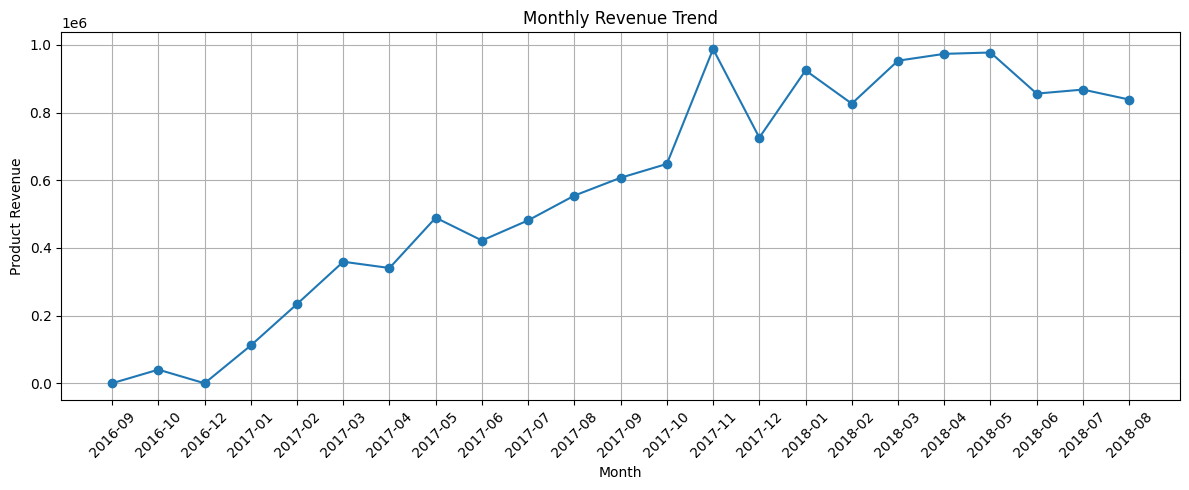

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(monthly_sales['year'].astype(str) + '-' +
         monthly_sales['month'].astype(str).str.zfill(2),
         monthly_sales['product_revenue'],
         marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Product Revenue')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [48]:
yearly_sales = (monthly_sales.groupby('year')['product_revenue'].sum().reset_index())

print(yearly_sales)

   year  product_revenue
0  2016         40470.98
1  2017       5962902.01
2  2018       7218125.12


In [49]:
yearly_sales['revenue_growth_pct'] = (
    yearly_sales['product_revenue'].pct_change()*100
)

print(yearly_sales)

   year  product_revenue  revenue_growth_pct
0  2016         40470.98                 NaN
1  2017       5962902.01        14633.772224
2  2018       7218125.12           21.050541


In [50]:
yearly_revenue = (delivered_sales.groupby('year')
                  ['product_revenue'].sum().
                  reset_index())
print(yearly_revenue)

   year  product_revenue
0  2016         40470.98
1  2017       5962902.01
2  2018       7218125.12


In [51]:
total_product_revenue = delivered_customer_sales['product_revenue'].sum()

total_delivered_orders = delivered_customer_sales['order_id'].nunique()

aov = (total_product_revenue / total_delivered_orders)

total_unique_customers = delivered_customer_sales['customer_unique_id'].nunique()

print("Total product revenue:", total_product_revenue)
print("Total delivered orders:", total_delivered_orders)
print("Average Order Value (AOV):", aov)
print("Total unique customers:", total_unique_customers)


Total product revenue: 13221498.11
Total delivered orders: 96478
Average Order Value (AOV): 137.0415857501192
Total unique customers: 93358



## 8. Product and Category Performance

Analyze product and category-level sales performance to identify the major revenue-generating categories.

The analysis includes:

- Calculating revenue by product category.
- Identifying top-performing product categories.
- Comparing revenue contributions across categories.
- Understanding product performance patterns.
- Identifying categories with strong business potential.


In [52]:
product_sales = order_items.merge(
    products,
    on='product_id',
    how='left'
)

print("Shape:", product_sales.shape)
print("/nFirst five rows:", product_sales.head())
print("\nColumn names:", product_sales.columns.tolist())

Shape: (112650, 15)
/nFirst five rows:                            order_id  ...  product_width_cm
0  00010242fe8c5a6d1ba2dd792cb16214  ...              14.0
1  00018f77f2f0320c557190d7a144bdd3  ...              40.0
2  000229ec398224ef6ca0657da4fc703e  ...              33.0
3  00024acbcdf0a6daa1e931b038114c75  ...              15.0
4  00042b26cf59d7ce69dfabb4e55b4fd9  ...              30.0

[5 rows x 15 columns]

Column names: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


In [53]:
product_sales = product_sales.merge(
    category_translation,
    on='product_category_name',
    how='left'
)

print(product_sales.head())

print(product_sales.shape)


                           order_id  ...  product_category_name_english
0  00010242fe8c5a6d1ba2dd792cb16214  ...                     cool_stuff
1  00018f77f2f0320c557190d7a144bdd3  ...                       pet_shop
2  000229ec398224ef6ca0657da4fc703e  ...                furniture_decor
3  00024acbcdf0a6daa1e931b038114c75  ...                      perfumery
4  00042b26cf59d7ce69dfabb4e55b4fd9  ...                   garden_tools

[5 rows x 16 columns]


(112650, 16)


In [54]:
print("Missing Portuguese Categories:")
print(product_sales['product_category_name'].isnull().sum())

print("\nMissing English Categories:")
print(product_sales['product_category_name_english'].isnull().sum())

missing_percentage = (
    product_sales['product_category_name_english'].isnull().mean() * 100
)

print("\nMissing English Category  Percentage:", round(missing_percentage, 2), "%")

Missing Portuguese Categories:
1603

Missing English Categories:
1627

Missing English Category  Percentage: 1.44 %


In [55]:
category_revenue = (
    product_sales.groupby('product_category_name_english')['price']
    .sum()
    .reset_index()
)

category_revenue = category_revenue.sort_values(
    by='price',
    ascending=False
).reset_index(drop=True)

print(category_revenue.head(10))

  product_category_name_english       price
0                 health_beauty  1258681.34
1                 watches_gifts  1205005.68
2                bed_bath_table  1036988.68
3                sports_leisure   988048.97
4         computers_accessories   911954.32
5               furniture_decor   729762.49
6                    cool_stuff   635290.85
7                    housewares   632248.66
8                          auto   592720.11
9                  garden_tools   485256.46


In [56]:
print(category_revenue.head())

  product_category_name_english       price
0                 health_beauty  1258681.34
1                 watches_gifts  1205005.68
2                bed_bath_table  1036988.68
3                sports_leisure   988048.97
4         computers_accessories   911954.32


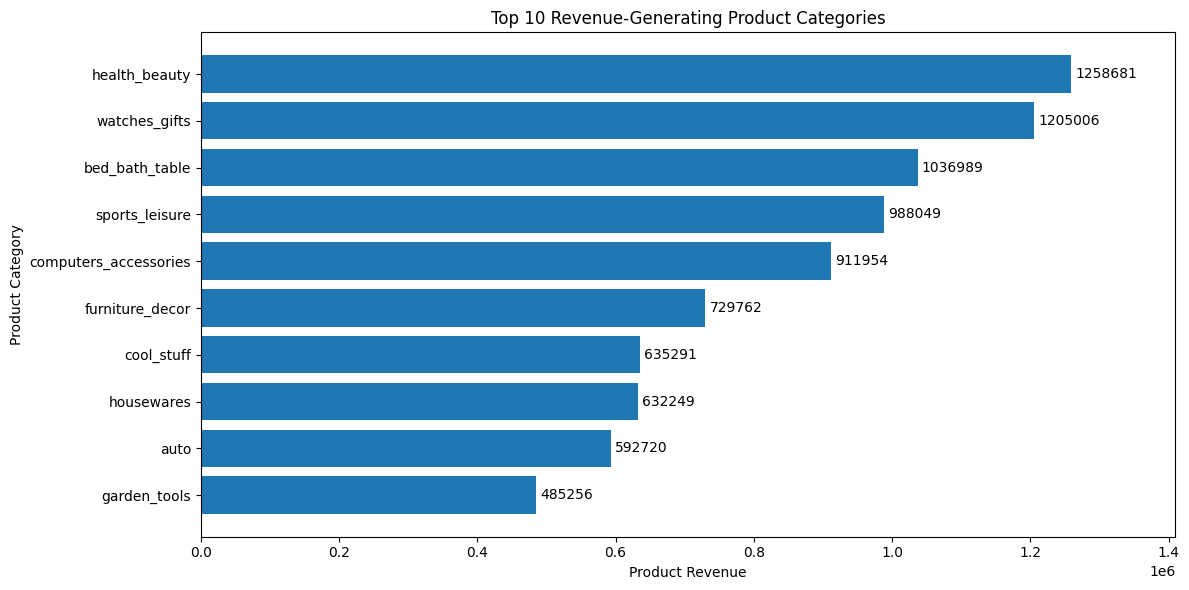

In [57]:
import matplotlib.pyplot as plt

top_10_categories = category_revenue.head(10)

plt.figure(figsize=(12, 6))

bars = plt.barh(top_10_categories['product_category_name_english'],
         top_10_categories['price'])

plt.xlim(0, top_10_categories['price'].max() * 1.12)
plt.bar_label(bars, fmt='%.0f', padding=3)
plt.title('Top 10 Revenue-Generating Product Categories')
plt.xlabel('Product Revenue')
plt.ylabel('Product Category')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [58]:
category_orders = (
    product_sales.groupby('product_category_name_english')['product_id']
    .count().reset_index()
)

category_orders = category_orders.sort_values(
    by='product_id',
    ascending=False
).reset_index(drop=True)

category_orders.head(10)

,product_category_name_english,product_id
0,bed_bath_table,11115
1,health_beauty,9670
2,sports_leisure,8641
3,furniture_decor,8334
4,computers_accessories,7827
5,housewares,6964
6,watches_gifts,5991
7,telephony,4545
8,garden_tools,4347
9,auto,4235


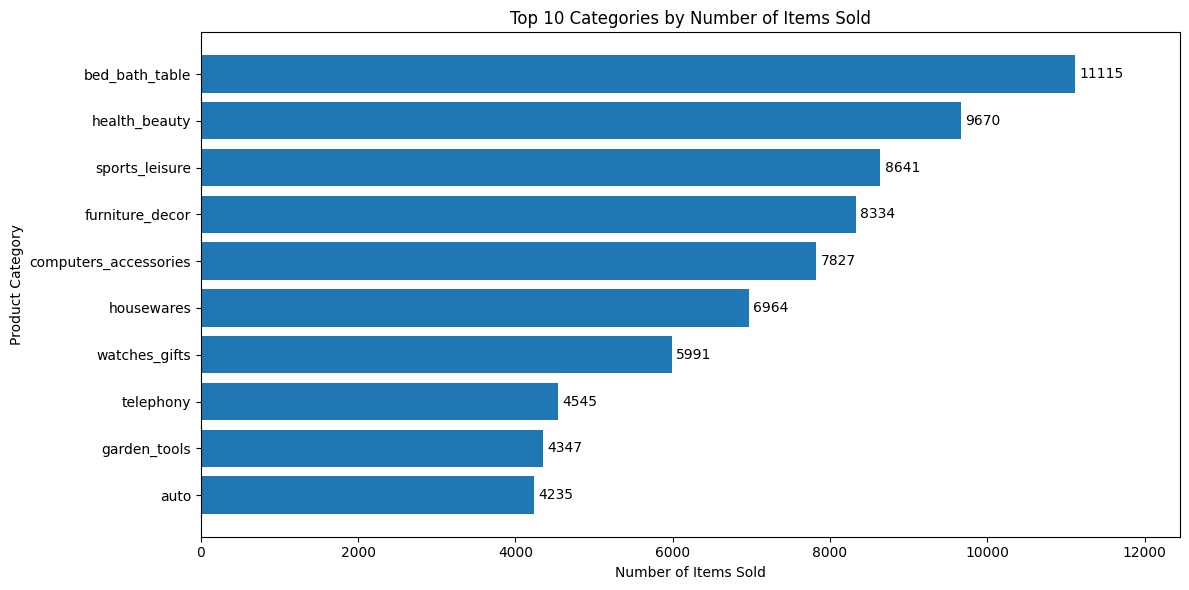

In [59]:
import matplotlib.pyplot as plt 

top_10_orders = category_orders.head(10)

plt.figure(figsize=(12, 6))

bars = plt.barh(top_10_orders['product_category_name_english'],
                top_10_orders['product_id']
                )

plt.title('Top 10 Categories by Number of Items Sold')
plt.xlabel('Number of Items Sold')
plt.ylabel('Product Category')

plt.gca().invert_yaxis()

plt.xlim(0, top_10_orders['product_id'].max() * 1.12)
plt.bar_label(bars, fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()

In [60]:
category_performance = category_revenue.merge(
    category_orders,
    on='product_category_name_english',
    how='inner'
)

category_performance = category_performance.rename(
    columns={
        'price': 'total_revenue',
        'product_id': 'items_sold'
    }
)

category_performance = category_performance.sort_values(
    by='total_revenue',
    ascending=False
)

category_performance.head(10)

,product_category_name_english,total_revenue,items_sold
0,health_beauty,1258681.34,9670
1,watches_gifts,1205005.68,5991
2,bed_bath_table,1036988.68,11115
3,sports_leisure,988048.97,8641
4,computers_accessories,911954.32,7827
5,furniture_decor,729762.49,8334
6,cool_stuff,635290.85,3796
7,housewares,632248.66,6964
8,auto,592720.11,4235
9,garden_tools,485256.46,4347



## 9. Customer Behaviour and Retention Analysis

Analyze customer purchasing patterns to understand customer engagement and repeat-purchase behaviour.

The analysis includes:

- Identifying unique customers.
- Calculating total orders per customer.
- Identifying one-time and repeat customers.
- Analyzing customer purchasing frequency.
- Examining customer revenue contribution.
- Understanding customer retention patterns.


In [61]:
customer_frequency = (delivered_customer_sales
                      .groupby('customer_unique_id')['order_id']
                      .nunique()
                      .reset_index()
                      .rename(columns={'order_id': 'total_orders'})
)

customer_frequency.sort_values(
    by = 'total_orders',
    ascending = False
).head(20)

,customer_unique_id,total_orders
51431,8d50f5eadf50201ccdcedfb9e2ac8455,15
22779,3e43e6105506432c953e165fb2acf44c,9
36706,6469f99c1f9dfae7733b25662e7f1782,7
73921,ca77025e7201e3b30c44b472ff346268,7
10060,1b6c7548a2a1f9037c1fd3ddfed95f33,7
87885,f0e310a6839dce9de1638e0fe5ab282a,6
26257,47c1a3033b8b77b3ab6e109eb4d5fdf3,6
6964,12f5d6e1cbf93dafd9dcc19095df0b3d,6
36500,63cfc61cee11cbe306bff5857d00bfe4,6
80538,dc813062e0fc23409cd255f7f53c7074,6


In [62]:
frequency_distribution = (
    customer_frequency['total_orders']
    .value_counts()
    .sort_index()
)

print(frequency_distribution)

total_orders
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64


In [63]:
one_time_customers = len(
    customer_frequency[customer_frequency['total_orders'] == 1]
)

repeat_customers = len(
    customer_frequency[customer_frequency['total_orders'] > 1]
)

total_customers = len(customer_frequency)

one_time_percentage = (
    one_time_customers / total_customers
) * 100

repeat_percentage = (
    repeat_customers / total_customers
) * 100


print("Total one-time customers:", one_time_customers)
print("Total repeat customers:", repeat_customers)
print("Percentage of one-time customers:", round(one_time_percentage, 2), "%")
print("Percentage of repeat customers:", round(repeat_percentage, 2), "%")

Total one-time customers: 90557
Total repeat customers: 2801
Percentage of one-time customers: 97.0 %
Percentage of repeat customers: 3.0 %


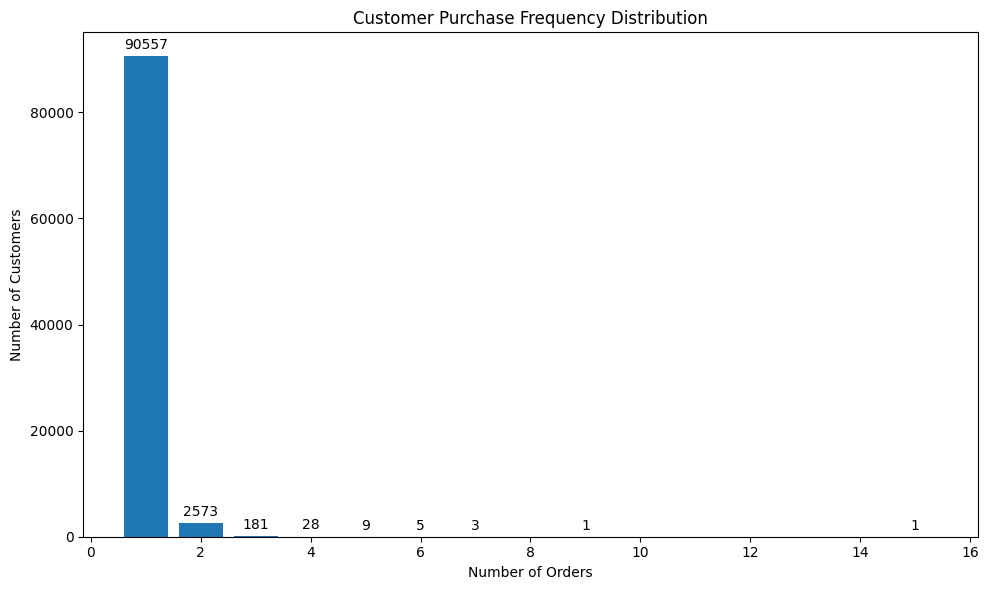

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    frequency_distribution.index,
    frequency_distribution.values
)

plt.title('Customer Purchase Frequency Distribution')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')

plt.bar_label(bars, fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()

In [65]:
customer_revenue = (
    delivered_customer_sales
    .groupby('customer_unique_id')['product_revenue']
    .sum()
    .reset_index()
    .rename(columns={'product_revenue': 'customer_revenue'})
    .sort_values(by='customer_revenue', ascending=False)
)

customer_revenue = customer_revenue.reset_index(drop=True)

customer_revenue.head(10)

,customer_unique_id,customer_revenue
0,0a0a92112bd4c708ca5fde585afaa872,13440.0
1,da122df9eeddfedc1dc1f5349a1a690c,7388.0
2,763c8b1c9c68a0229c42c9fc6f662b93,7160.0
3,dc4802a71eae9be1dd28f5d788ceb526,6735.0
4,459bef486812aa25204be022145caa62,6729.0
5,ff4159b92c40ebe40454e3e6a7c35ed6,6499.0
6,4007669dec559734d6f53e029e360987,5934.6
7,eebb5dda148d3893cdaf5b5ca3040ccb,4690.0
8,48e1ac109decbb87765a3eade6854098,4590.0
9,a229eba70ec1c2abef51f04987deb7a5,4400.0


In [66]:
# 1. Total customer revenue
total_customer_revenue = customer_revenue['customer_revenue'].sum()

# 2. Total unique customers
total_unique_customers = customer_revenue['customer_unique_id'].nunique()

# 3. Average customer revenue
average_customer_revenue = (
    total_customer_revenue / total_unique_customers
)

# Display results
print("Total Customer Revenue:", round(total_customer_revenue, 2))
print("Total Unique Customers:", total_unique_customers)
print("Average Customer Revenue:", round(average_customer_revenue, 2))

Total Customer Revenue: 13221498.11
Total Unique Customers: 93358
Average Customer Revenue: 141.62


In [67]:
# 1. Filter repeat customers
repeat_customer_data = customer_frequency[
    customer_frequency['total_orders'] > 1
]

# 2. Merge with customer revenue
repeat_customer_analysis = repeat_customer_data.merge(
    customer_revenue,
    on='customer_unique_id',
    how='inner'
)

# 3. Sort by total orders (highest to lowest)
repeat_customer_analysis = repeat_customer_analysis.sort_values(
    by='total_orders',
    ascending=False
)

# 4. Display top 10 customers
repeat_customer_analysis.head(10)

,customer_unique_id,total_orders,customer_revenue
1551,8d50f5eadf50201ccdcedfb9e2ac8455,15,714.63
670,3e43e6105506432c953e165fb2acf44c,9,1000.85
308,1b6c7548a2a1f9037c1fd3ddfed95f33,7,809.21
1089,6469f99c1f9dfae7733b25662e7f1782,7,664.20
2233,ca77025e7201e3b30c44b472ff346268,7,806.61
767,47c1a3033b8b77b3ab6e109eb4d5fdf3,6,836.60
2426,dc813062e0fc23409cd255f7f53c7074,6,687.76
209,12f5d6e1cbf93dafd9dcc19095df0b3d,6,58.40
2663,f0e310a6839dce9de1638e0fe5ab282a,6,438.09
1078,63cfc61cee11cbe306bff5857d00bfe4,6,579.81


In [68]:
# 1. Average delivered orders per unique customer
average_orders = customer_frequency['total_orders'].mean()

# 2. Maximum orders placed by a single customer
maximum_orders = customer_frequency['total_orders'].max()

# 3. Median orders per customer
median_orders = customer_frequency['total_orders'].median()

# Display results
print("Average Orders per Customer:", round(average_orders, 2))
print("Maximum Orders by a Single Customer:", maximum_orders)
print("Median Orders per Customer:", median_orders)

Average Orders per Customer: 1.03
Maximum Orders by a Single Customer: 15
Median Orders per Customer: 1.0


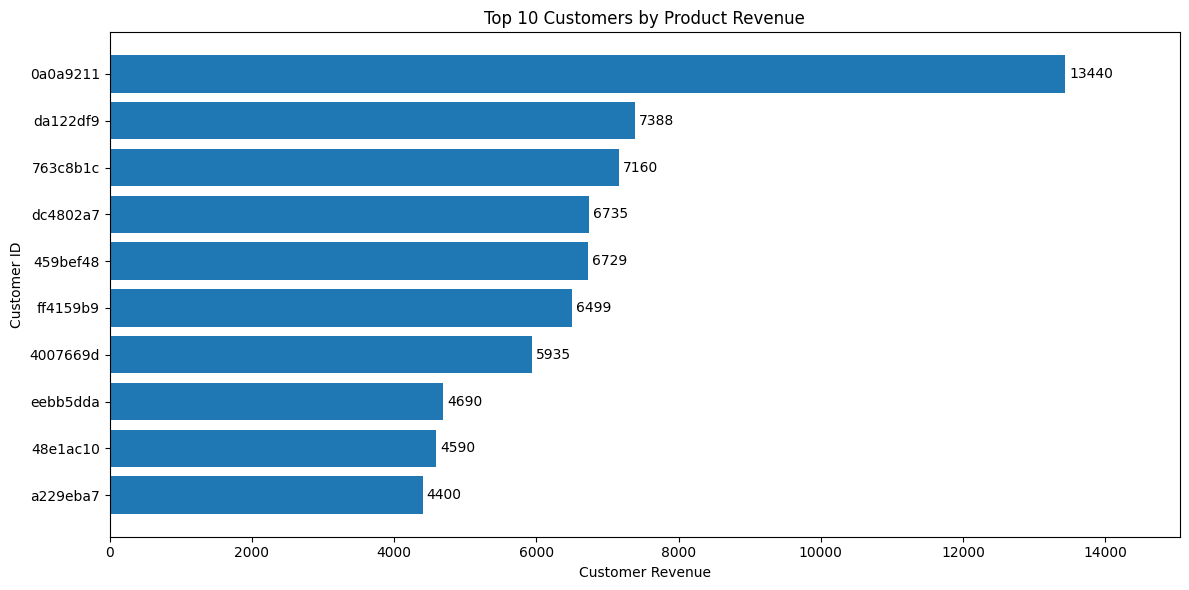

In [69]:
import matplotlib.pyplot as plt

# 1. Select top 10 customers
top_10_customers = customer_revenue.head(10)

# 2. Create horizontal bar chart
plt.figure(figsize=(12, 6))

bars = plt.barh(
    top_10_customers['customer_unique_id'].str[:8],
    top_10_customers['customer_revenue']
)

# 3. Add title and axis labels
plt.title('Top 10 Customers by Product Revenue')
plt.xlabel('Customer Revenue')
plt.ylabel('Customer ID')

# 4. Put highest-revenue customer at the top
plt.gca().invert_yaxis()

# 5. Display revenue values on bars
plt.bar_label(bars, fmt='%.0f', padding=3)

# 6. Add extra space for revenue labels
plt.xlim(0, top_10_customers['customer_revenue'].max() * 1.12)

# 7. Display chart
plt.tight_layout()
plt.show()

In [70]:
print(customer_revenue.head(1))
print(customer_frequency.sort_values(
    by='total_orders', ascending=False
).head(1))

                 customer_unique_id  customer_revenue
0  0a0a92112bd4c708ca5fde585afaa872           13440.0
                     customer_unique_id  total_orders
51431  8d50f5eadf50201ccdcedfb9e2ac8455            15


In [71]:
customer_order_counts = delivered_customer_sales['customer_unique_id'].value_counts()

total_unique_customers = customer_order_counts.count()

repeated_customers = customer_order_counts[customer_order_counts > 1]
total_repeat_customers = len(repeated_customers)

repeat_customer_percentage = (
    total_repeat_customers / total_unique_customers
) * 100


print("Total Unique Customers:", total_unique_customers)
print("Repeat Customers:", total_repeat_customers)
print("Repeat Customer Percentage:", round(repeat_customer_percentage, 2), "%")


Total Unique Customers: 93358
Repeat Customers: 2801
Repeat Customer Percentage: 3.0 %


## 10. Historical Monthly Revenue Analysis

Explore how product revenue changed over time using monthly aggregation, percentage change, and a three-month moving average.

This section describes historical patterns only. It does not claim to predict future sales.


In [72]:
delivered_customer_sales['order_purchase_timestamp'] = pd.to_datetime(
    delivered_customer_sales['order_purchase_timestamp']
)

delivered_customer_sales['year'] = (delivered_customer_sales['order_purchase_timestamp'].dt.year)

delivered_customer_sales['month'] = (delivered_customer_sales['order_purchase_timestamp'].dt.month)

monthly_revenue = (delivered_customer_sales.groupby(['year', 'month']) ['product_revenue'].sum().reset_index())

monthly_revenue = monthly_revenue.sort_values(by=['year', 'month']).reset_index(drop=True)

print(monthly_revenue)

    year  month  product_revenue
0   2016      9           134.97
1   2016     10         40325.11
2   2016     12            10.90
3   2017      1        111798.36
4   2017      2        234223.40
5   2017      3        359198.85
6   2017      4        340669.68
7   2017      5        489338.25
8   2017      6        421923.37
9   2017      7        481604.52
10  2017      8        554699.70
11  2017      9        607399.67
12  2017     10        648247.65
13  2017     11        987765.37
14  2017     12        726033.19
15  2018      1        924645.00
16  2018      2        826437.13
17  2018      3        953356.25
18  2018      4        973534.09
19  2018      5        977544.69
20  2018      6        856077.86
21  2018      7        867953.46
22  2018      8        838576.64


In [73]:
highest_revenue_index = monthly_revenue['product_revenue'].idxmax()

highest_revenue_month = monthly_revenue.loc[highest_revenue_index]

print("Year:", highest_revenue_month['year'])
print("Month:", highest_revenue_month['month'])
print("Highest Product Revenue:", highest_revenue_month['product_revenue'])

Year: 2017.0
Month: 11.0
Highest Product Revenue: 987765.37


In [74]:
monthly_revenue['revenue_growth_pct'] = (monthly_revenue['product_revenue'].pct_change()*100)

print(monthly_revenue)

    year  month  product_revenue  revenue_growth_pct
0   2016      9           134.97                 NaN
1   2016     10         40325.11        2.977709e+04
2   2016     12            10.90       -9.997297e+01
3   2017      1        111798.36        1.025573e+06
4   2017      2        234223.40        1.095052e+02
5   2017      3        359198.85        5.335737e+01
6   2017      4        340669.68       -5.158471e+00
7   2017      5        489338.25        4.364009e+01
8   2017      6        421923.37       -1.377674e+01
9   2017      7        481604.52        1.414502e+01
10  2017      8        554699.70        1.517743e+01
11  2017      9        607399.67        9.500631e+00
12  2017     10        648247.65        6.725058e+00
13  2017     11        987765.37        5.237469e+01
14  2017     12        726033.19       -2.649740e+01
15  2018      1        924645.00        2.735575e+01
16  2018      2        826437.13       -1.062114e+01
17  2018      3        953356.25        1.5357

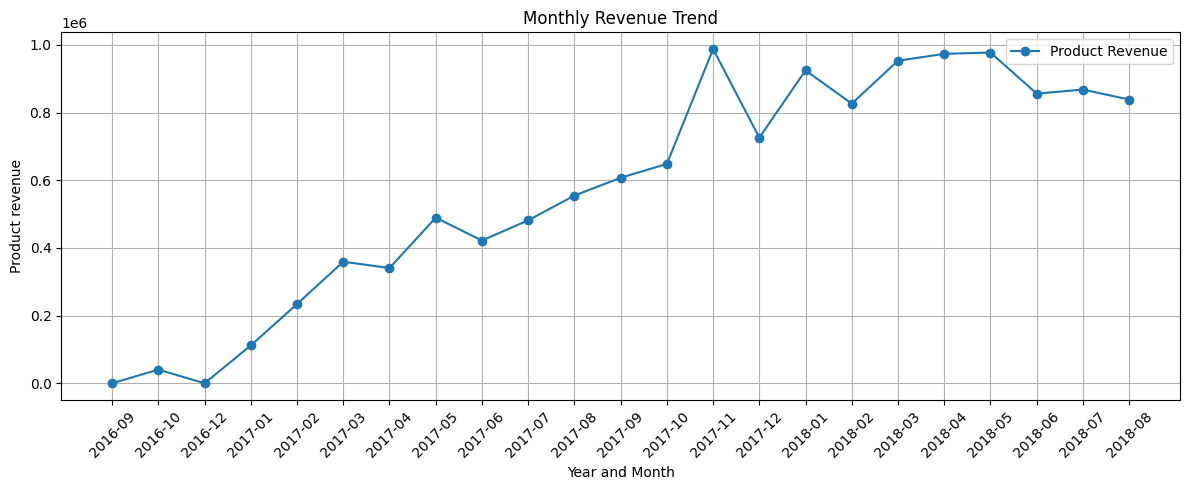

In [75]:
import matplotlib.pyplot as plt


plt.figure(figsize=(12, 5))

plt.plot(monthly_revenue['year'].astype(str) + '-' + monthly_revenue['month'].astype(str).str.zfill(2), monthly_revenue['product_revenue'], marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Year and Month")
plt.ylabel("Product revenue")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.legend(["Product Revenue"])

plt.show()

In [76]:
total_product_revenue = monthly_revenue.groupby('year')['product_revenue'].sum().reset_index()
print(total_product_revenue)

   year  product_revenue
0  2016         40470.98
1  2017       5962902.01
2  2018       7218125.12


In [77]:
total_product_revenue['revenue_growth_pct'] = (total_product_revenue['product_revenue'].pct_change()*100)
print(total_product_revenue)

   year  product_revenue  revenue_growth_pct
0  2016         40470.98                 NaN
1  2017       5962902.01        14633.772224
2  2018       7218125.12           21.050541


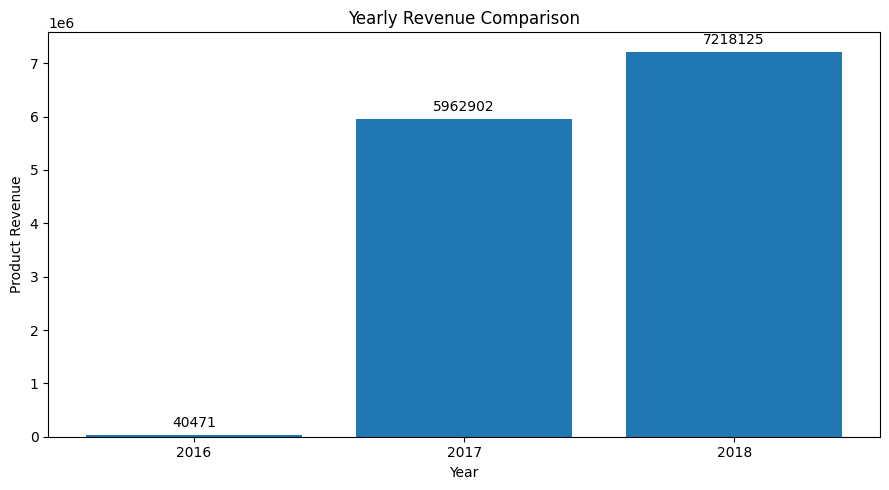

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    total_product_revenue['year'].astype(str),
    total_product_revenue['product_revenue']
)

plt.title('Yearly Revenue Comparison')
plt.xlabel('Year')
plt.ylabel('Product Revenue')

plt.bar_label(bars, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

In [79]:
print(total_product_revenue)

   year  product_revenue  revenue_growth_pct
0  2016         40470.98                 NaN
1  2017       5962902.01        14633.772224
2  2018       7218125.12           21.050541


In [80]:
delivered_customer_sales['order_purchase_timestamp'] = pd.to_datetime(
    delivered_customer_sales['order_purchase_timestamp']
)

delivered_customer_sales['year'] = (
    delivered_customer_sales['order_purchase_timestamp'].dt.year
)

delivered_customer_sales['month'] = (
    delivered_customer_sales['order_purchase_timestamp'].dt.month
)

monthly_revenue = (
    delivered_customer_sales
    .groupby(['year', 'month'])['product_revenue']
    .sum()
    .reset_index()
)

monthly_revenue['date'] = pd.to_datetime(
    monthly_revenue[['year', 'month']].assign(day=1)
)

monthly_revenue = monthly_revenue.sort_values(
    by='date'
)

monthly_revenue = monthly_revenue[
    ['date', 'product_revenue']
].reset_index(drop=True)

monthly_revenue.head()

,date,product_revenue
0,2016-09-01,134.97
1,2016-10-01,40325.11
2,2016-12-01,10.90
3,2017-01-01,111798.36
4,2017-02-01,234223.40


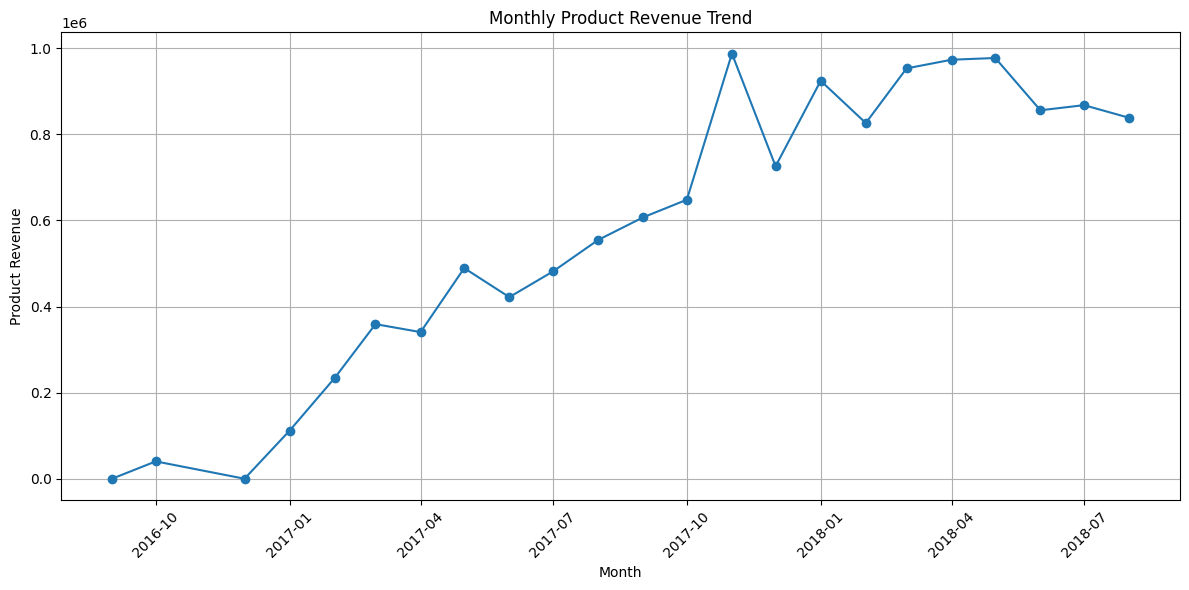

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue['date'],
    monthly_revenue['product_revenue'],
    marker='o'
)

plt.title('Monthly Product Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Product Revenue')

plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [82]:
max_revenue_month = monthly_revenue.loc[
    monthly_revenue['product_revenue'].idxmax()
]

min_revenue_month = monthly_revenue.loc[
    monthly_revenue['product_revenue'].idxmin()
]

print("Highest Renvenue Month:")
print("Date:", max_revenue_month['date'])
print("Revenue:", max_revenue_month['product_revenue'])

print("\nLowest Revenue Month:")
print("Date:", min_revenue_month['date'])
print("Revenue:", min_revenue_month['product_revenue'])

Highest Renvenue Month:
Date: 2017-11-01 00:00:00
Revenue: 987765.37

Lowest Revenue Month:
Date: 2016-12-01 00:00:00
Revenue: 10.9


In [83]:
monthly_revenue['revenue_growth_pct'] = (
    monthly_revenue['product_revenue'].pct_change() * 100
)

print(monthly_revenue[
    ['date', 'product_revenue', 'revenue_growth_pct']
]
)

         date  product_revenue  revenue_growth_pct
0  2016-09-01           134.97                 NaN
1  2016-10-01         40325.11        2.977709e+04
2  2016-12-01            10.90       -9.997297e+01
3  2017-01-01        111798.36        1.025573e+06
4  2017-02-01        234223.40        1.095052e+02
5  2017-03-01        359198.85        5.335737e+01
6  2017-04-01        340669.68       -5.158471e+00
7  2017-05-01        489338.25        4.364009e+01
8  2017-06-01        421923.37       -1.377674e+01
9  2017-07-01        481604.52        1.414502e+01
10 2017-08-01        554699.70        1.517743e+01
11 2017-09-01        607399.67        9.500631e+00
12 2017-10-01        648247.65        6.725058e+00
13 2017-11-01        987765.37        5.237469e+01
14 2017-12-01        726033.19       -2.649740e+01
15 2018-01-01        924645.00        2.735575e+01
16 2018-02-01        826437.13       -1.062114e+01
17 2018-03-01        953356.25        1.535738e+01
18 2018-04-01        973534.09 

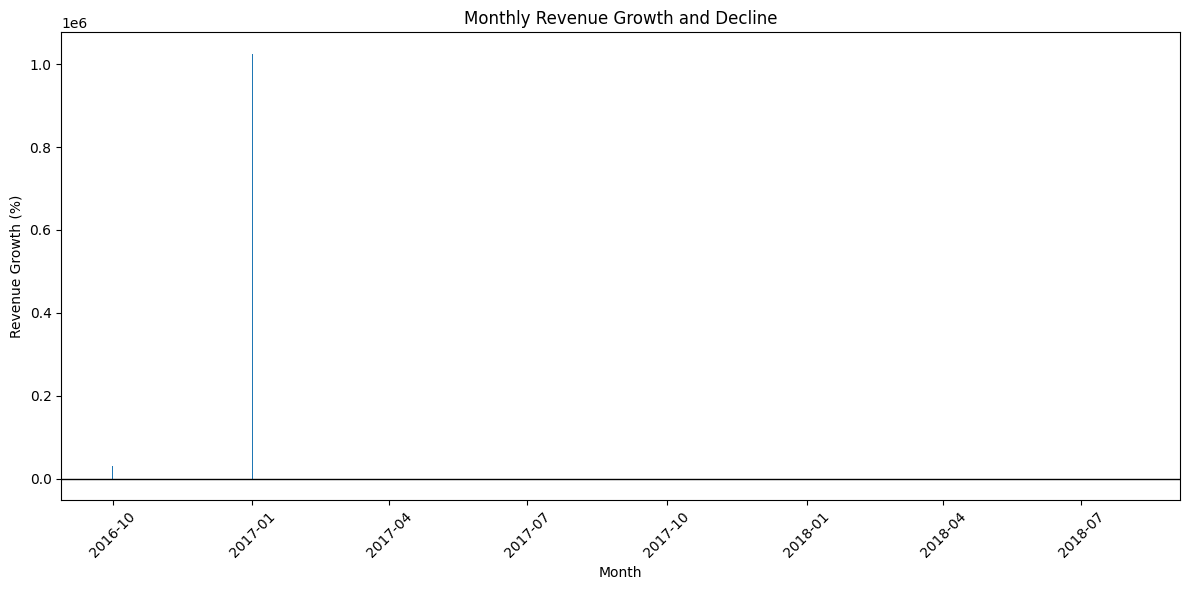

In [84]:
import matplotlib.pyplot as plt

monthly_revenue['revenue_growth_pct'] = (
    monthly_revenue['product_revenue'].pct_change() * 100
)

plt.figure(figsize = (12, 6))

bars = plt.bar(
    monthly_revenue['date'],
    monthly_revenue['revenue_growth_pct']
)

plt.axhline(y=0, color='black', linewidth=1)

plt.title('Monthly Revenue Growth and Decline')
plt.xlabel('Month')
plt.ylabel('Revenue Growth (%)')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [85]:
monthly_revenue['moving_avg_3_month'] = (
    monthly_revenue['product_revenue']
    .rolling(window=3)
    .mean()
)

# 2. Display required columns
monthly_revenue[
    ['date', 'product_revenue', 'moving_avg_3_month']
]

,date,product_revenue,moving_avg_3_month
0,2016-09-01,134.97,NaN
1,2016-10-01,40325.11,NaN
2,2016-12-01,10.90,13490.326667
3,2017-01-01,111798.36,50711.456667
4,2017-02-01,234223.40,115344.220000
5,2017-03-01,359198.85,235073.536667
6,2017-04-01,340669.68,311363.976667
7,2017-05-01,489338.25,396402.260000
8,2017-06-01,421923.37,417310.433333
9,2017-07-01,481604.52,464288.713333


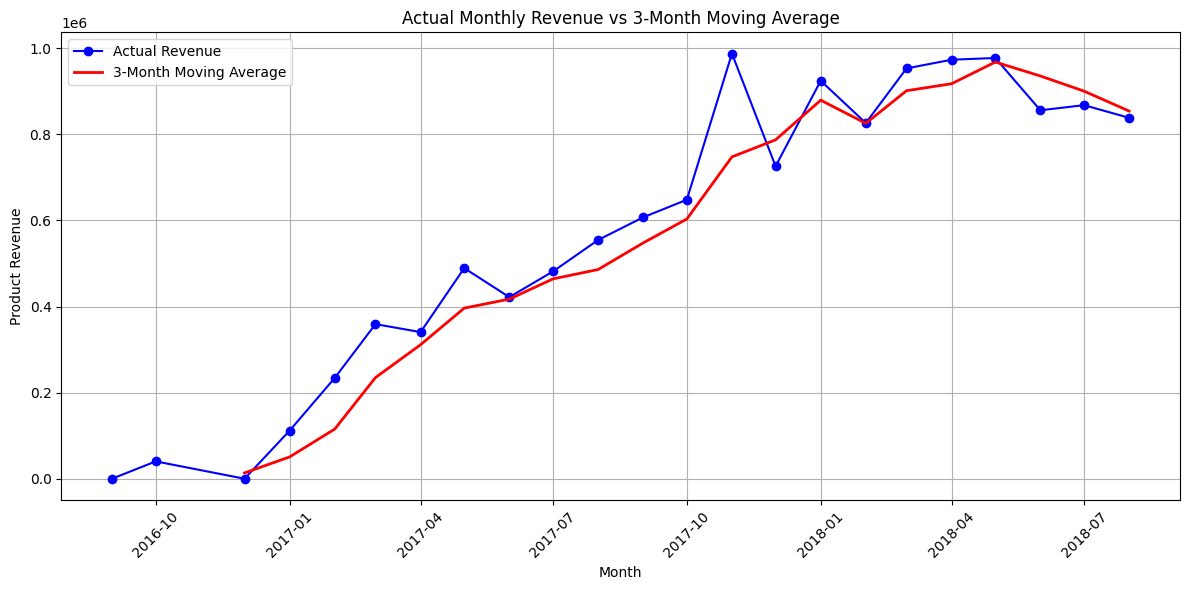

In [86]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue['date'],
    monthly_revenue['product_revenue'],
    color='blue',
    marker='o',
    label='Actual Revenue'
)

plt.plot(
    monthly_revenue['date'],
    monthly_revenue['moving_avg_3_month'],
    color='red',
    linewidth=2,
    label='3-Month Moving Average'
)

plt.title('Actual Monthly Revenue vs 3-Month Moving Average')
plt.xlabel('Month')
plt.ylabel('Product Revenue')

plt.xticks(rotation=45)

plt.legend()

plt.grid(True)
plt.tight_layout()
plt.show()

## 11. Customer Churn Analysis and Dataset Preparation

For this project, churn is defined as **no order placed during the 180 days after the feature cutoff date**.

We use:
- Historical customer order count.
- Historical customer revenue.
- Days since the customer's last historical purchase.

The prediction window is kept separate from the historical feature window to avoid using future activity as an input feature. This is an operational definition of inactivity for this dataset, not a claim that a customer will never return.


In [87]:
# Define new cutoff and prediction window
feature_cutoff_new = pd.Timestamp('2018-04-01')

prediction_end_new = (
    feature_cutoff_new + pd.Timedelta(days=180)
)

# Ensure timestamps are datetime values before date calculations
orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

# Check dataset coverage
dataset_end = orders['order_purchase_timestamp'].max()

actual_days = (dataset_end - feature_cutoff_new).days

print("New feature cutoff:", feature_cutoff_new)
print("180-day prediction end:", prediction_end_new)
print("Dataset end:", dataset_end)

print("\nRequired observation days: 180")
print("Available observation days:", actual_days)
print("Observation window fully covered:",
      dataset_end >= prediction_end_new)

New feature cutoff: 2018-04-01 00:00:00
180-day prediction end: 2018-09-28 00:00:00
Dataset end: 2018-10-17 17:30:18

Required observation days: 180
Available observation days: 199
Observation window fully covered: True


In [88]:
# Historical feature window
feature_data_new = delivered_customer_sales[
    delivered_customer_sales['order_purchase_timestamp']
    < feature_cutoff_new
].copy()

print("New feature dataset shape:", feature_data_new.shape)

print("\nDate range:")
print("Start:", feature_data_new['order_purchase_timestamp'].min())
print("End:", feature_data_new['order_purchase_timestamp'].max())

print("\nUnique customers:",
      feature_data_new['customer_unique_id'].nunique())

print("Unique orders:",
      feature_data_new['order_id'].nunique())

New feature dataset shape: (64322, 8)

Date range:
Start: 2016-09-15 12:16:38
End: 2018-03-31 23:54:10

Unique customers: 62299
Unique orders: 64322


In [89]:
# Historical order frequency
feature_orders_new = (
    feature_data_new
    .groupby('customer_unique_id')
    .agg(feature_total_orders=('order_id', 'nunique'))
    .reset_index()
)

# Historical revenue
feature_revenue_new = (
    feature_data_new
    .groupby('customer_unique_id')
    .agg(feature_total_revenue=('product_revenue', 'sum'))
    .reset_index()
)

# Last purchase date
feature_recency_new = (
    feature_data_new
    .groupby('customer_unique_id')
    .agg(
        feature_last_purchase_date=(
            'order_purchase_timestamp', 'max'
        )
    )
    .reset_index()
)

# Combine features
customer_features_new = feature_orders_new.merge(
    feature_revenue_new,
    on='customer_unique_id'
).merge(
    feature_recency_new,
    on='customer_unique_id'
)

# Calculate recency
customer_features_new['feature_days_since_last_purchase'] = (
    feature_cutoff_new -
    customer_features_new['feature_last_purchase_date']
).dt.days

print("New customer features shape:",
      customer_features_new.shape)

display(customer_features_new.head())

New customer features shape: (62299, 5)


,customer_unique_id,feature_total_orders,feature_total_revenue,feature_last_purchase_date,feature_days_since_last_purchase
0,0000f46a3911fa3c0805444483337064,1,69.00,2017-03-10 21:05:03,386
1,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,2017-10-12 20:29:41,170
2,0004aac84e0df4da2b147fca70cf8255,1,180.00,2017-11-14 19:45:42,137
3,00053a61a98854899e70ed204dd4bafe,1,382.00,2018-02-28 11:15:41,31
4,0005e1862207bf6ccc02e4228effd9a0,1,135.00,2017-03-04 23:32:12,392


In [90]:
# Define 180-day prediction window
prediction_data_new = orders[
    (orders['order_purchase_timestamp'] >= feature_cutoff_new) &
    (orders['order_purchase_timestamp'] < prediction_end_new)
].merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

# Count orders per customer
prediction_activity_new = (
    prediction_data_new
    .groupby('customer_unique_id')
    .agg(
        prediction_total_orders=('order_id', 'nunique')
    )
    .reset_index()
)

print("Prediction dataset shape:",
      prediction_data_new.shape)

print("Customers with prediction activity:",
      prediction_activity_new['customer_unique_id'].nunique())

print("\nOrder status distribution:")
print(prediction_data_new['order_status'].value_counts())

display(prediction_activity_new.head())

Prediction dataset shape: (32798, 9)
Customers with prediction activity: 32253

Order status distribution:
order_status
delivered      32156
shipped          304
canceled         196
invoiced          77
unavailable       50
processing        15
Name: count, dtype: int64


,customer_unique_id,prediction_total_orders
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0004bd2a26a76fe21f786e4fbd80607f,1
3,00050ab1314c0e55a6ca13cf7181fecf,1
4,000949456b182f53c18b68d6babc79c1,1


In [91]:
# Merge historical customer cohort with prediction activity
churn_data_new = customer_features_new.merge(
    prediction_activity_new,
    on='customer_unique_id',
    how='left'
)

# Fill missing prediction orders
churn_data_new['prediction_total_orders'] = (
    churn_data_new['prediction_total_orders'].fillna(0)
)

churn_data_new['prediction_total_orders'] = (
    churn_data_new['prediction_total_orders'].astype(int)
)

# Create churn label
# 1 = No order during 180 days
# 0 = At least one order during 180 days
churn_data_new['churn'] = (
    churn_data_new['prediction_total_orders'] == 0
).astype(int)

print("New churn dataset shape:", churn_data_new.shape)

print("\nChurn distribution:")
print(churn_data_new['churn'].value_counts())

print("\nChurn percentages:")
print(churn_data_new['churn'].value_counts(normalize=True) * 100)

display(churn_data_new.head())

New churn dataset shape: (62299, 7)

Churn distribution:
churn
1    61688
0      611
Name: count, dtype: int64

Churn percentages:
churn
1    99.019246
0     0.980754
Name: proportion, dtype: float64


,customer_unique_id,feature_total_orders,feature_total_revenue,feature_last_purchase_date,feature_days_since_last_purchase,prediction_total_orders,churn
0,0000f46a3911fa3c0805444483337064,1,69.00,2017-03-10 21:05:03,386,0,1
1,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,2017-10-12 20:29:41,170,0,1
2,0004aac84e0df4da2b147fca70cf8255,1,180.00,2017-11-14 19:45:42,137,0,1
3,00053a61a98854899e70ed204dd4bafe,1,382.00,2018-02-28 11:15:41,31,0,1
4,0005e1862207bf6ccc02e4228effd9a0,1,135.00,2017-03-04 23:32:12,392,0,1


In [92]:
print("Historical orders per customer:")
print(
    churn_data_new['feature_total_orders']
    .value_counts()
    .sort_index()
)

print("\nPercentage distribution:")
print(
    churn_data_new['feature_total_orders']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nOne-time customers:",
      (churn_data_new['feature_total_orders'] == 1).sum())

print("Repeat customers:",
      (churn_data_new['feature_total_orders'] > 1).sum())

Historical orders per customer:
feature_total_orders
1    60470
2     1687
3      115
4       14
5        7
6        3
7        1
8        1
9        1
Name: count, dtype: int64

Percentage distribution:
feature_total_orders
1    97.064158
2     2.707909
3     0.184594
4     0.022472
5     0.011236
6     0.004815
7     0.001605
8     0.001605
9     0.001605
Name: proportion, dtype: float64

One-time customers: 60470
Repeat customers: 1829


In [93]:
churn_frequency_new = (
    churn_data_new
    .groupby('feature_total_orders')
    .agg(
        total_customers=('customer_unique_id', 'count'),
        churned_customers=('churn', 'sum')
    )
)

churn_frequency_new['active_customers'] = (
    churn_frequency_new['total_customers']
    - churn_frequency_new['churned_customers']
)

churn_frequency_new['churn_rate_pct'] = (
    churn_frequency_new['churned_customers']
    / churn_frequency_new['total_customers'] * 100
)

churn_frequency_new['active_rate_pct'] = (
    churn_frequency_new['active_customers']
    / churn_frequency_new['total_customers'] * 100
)

display(churn_frequency_new)

,total_customers,churned_customers,active_customers,churn_rate_pct,active_rate_pct
feature_total_orders,,,,,
1,60470,59921,549,99.092112,0.907888
2,1687,1645,42,97.510373,2.489627
3,115,103,12,89.565217,10.434783
4,14,11,3,78.571429,21.428571
5,7,4,3,57.142857,42.857143
6,3,2,1,66.666667,33.333333
7,1,1,0,100.000000,0.000000
8,1,0,1,0.000000,100.000000
9,1,1,0,100.000000,0.000000


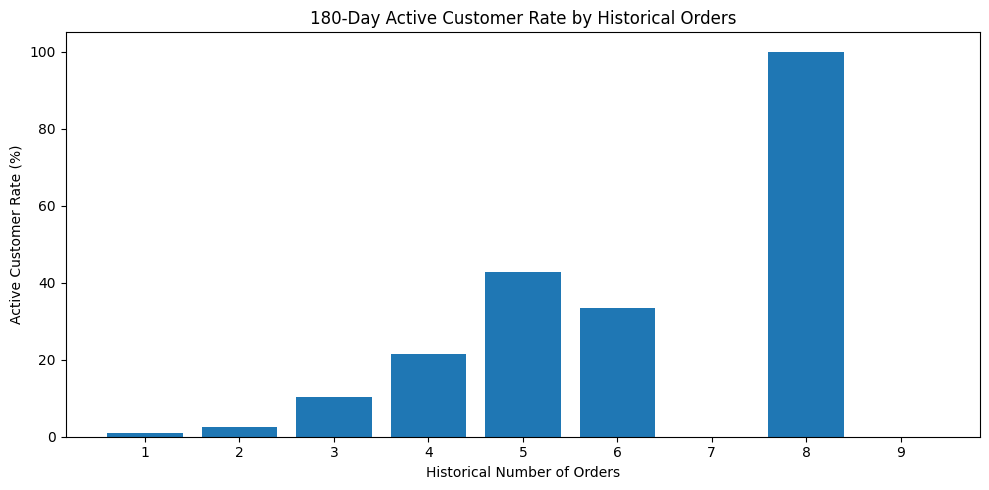

In [94]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    churn_frequency_new.index.astype(str),
    churn_frequency_new['active_rate_pct']
)

plt.title('180-Day Active Customer Rate by Historical Orders')
plt.xlabel('Historical Number of Orders')
plt.ylabel('Active Customer Rate (%)')

plt.tight_layout()
plt.show()

In [95]:
churn_data_new['recency_group'] = pd.cut(
    churn_data_new['feature_days_since_last_purchase'],
    bins=[-1, 30, 60, 90, 180, float('inf')],
    labels=['0-30 days', '31-60 days', '61-90 days',
            '91-180 days', '180+ days']
)

recency_analysis_new = (
    churn_data_new
    .groupby('recency_group', observed=False)
    .agg(
        total_customers=('customer_unique_id', 'count'),
        active_customers=('churn', lambda x: (x == 0).sum())
    )
)

recency_analysis_new['active_rate_pct'] = (
    recency_analysis_new['active_customers']
    / recency_analysis_new['total_customers'] * 100
)

display(recency_analysis_new)

print(
    "Total customers:",
    recency_analysis_new['total_customers'].sum()
)

,total_customers,active_customers,active_rate_pct
recency_group,,,
0-30 days,6913,91,1.316360
31-60 days,6864,97,1.413170
61-90 days,6504,77,1.183887
91-180 days,16640,146,0.877404
180+ days,25378,200,0.788084


Total customers: 62299


In [96]:
cohort_summary = pd.DataFrame({
    'Metric': [
        'Feature cutoff',
        'Prediction window',
        'Customers in cohort',
        'Churned customers',
        'Active customers',
        'Churn percentage',
        'Active percentage'
    ],
    'Value': [
        feature_cutoff_new.date(),
        '180 days',
        len(churn_data_new),
        int(churn_data_new['churn'].sum()),
        int((churn_data_new['churn'] == 0).sum()),
        round(churn_data_new['churn'].mean() * 100, 2),
        round((churn_data_new['churn'] == 0).mean() * 100, 2)
    ]
})

display(cohort_summary)


,Metric,Value
0,Feature cutoff,2018-04-01
1,Prediction window,180 days
2,Customers in cohort,62299
3,Churned customers,61688
4,Active customers,611
5,Churn percentage,99.02
6,Active percentage,0.98


## 12. Machine Learning: Customer Churn Classification

Train a classification model to identify customers who place no order during the 180-day prediction window.

The workflow uses:
- Select input features (`X`) and target (`y`).
- Split data into training and testing sets.
- Stratified sampling.
- A simple `DummyClassifier` baseline.
- Logistic Regression.
- Accuracy, confusion matrix, precision, recall, and F1-score.

The churn target is highly imbalanced in this dataset. We will compare the model with a baseline and report its limitations honestly.


In [97]:
# Select input features
X = churn_data_new[
    [
        'feature_total_orders',
        'feature_days_since_last_purchase',
        'feature_total_revenue'
    ]
]

# Select target
y = churn_data_new['churn']

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.head())


X shape: (62299, 3)
y shape: (62299,)


,feature_total_orders,feature_days_since_last_purchase,feature_total_revenue
0,1,386,69.00
1,1,170,25.99
2,1,137,180.00
3,1,31,382.00
4,1,392,135.00


0    1
1    1
2    1
3    1
4    1
Name: churn, dtype: int64

In [98]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training features: (49839, 3)
Testing features: (12460, 3)

Training target distribution:
churn
1    99.018841
0     0.981159
Name: proportion, dtype: float64

Testing target distribution:
churn
1    99.020867
0     0.979133
Name: proportion, dtype: float64


In [99]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Baseline: always predict the most frequent class
dummy_model = DummyClassifier(strategy='most_frequent')
dummy_model.fit(X_train, y_train)

y_pred_dummy = dummy_model.predict(X_test)

print("Baseline Accuracy:", accuracy_score(y_test, y_pred_dummy))
print("\nBaseline Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dummy))
print("\nBaseline Classification Report:")
print(classification_report(y_test, y_pred_dummy, zero_division=0))


Baseline Accuracy: 0.9902086677367576

Baseline Confusion Matrix:
[[    0   122]
 [    0 12338]]

Baseline Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       122
           1       0.99      1.00      1.00     12338

    accuracy                           0.99     12460
   macro avg       0.50      0.50      0.50     12460
weighted avg       0.98      0.99      0.99     12460



In [100]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Scale numeric features, then train Logistic Regression
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)
y_pred_lr = logistic_model.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))
print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))


Logistic Regression Accuracy: 0.5774478330658106

Logistic Regression Confusion Matrix:
[[  62   60]
 [5205 7133]]

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.01      0.51      0.02       122
           1       0.99      0.58      0.73     12338

    accuracy                           0.58     12460
   macro avg       0.50      0.54      0.38     12460
weighted avg       0.98      0.58      0.72     12460



## 13. Model Evaluation and Interpretation

Compare the baseline with Logistic Regression using the classification metrics studied so far.

Because the churn classes may be highly imbalanced, accuracy should not be considered on its own. Read the confusion matrix and the precision, recall, and F1-score for each class before drawing conclusions.


In [101]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_comparison = pd.DataFrame({
    'Model': ['Dummy Baseline', 'Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_dummy),
        accuracy_score(y_test, y_pred_lr)
    ],
    'Churn Precision': [
        precision_score(y_test, y_pred_dummy, pos_label=1, zero_division=0),
        precision_score(y_test, y_pred_lr, pos_label=1, zero_division=0)
    ],
    'Churn Recall': [
        recall_score(y_test, y_pred_dummy, pos_label=1, zero_division=0),
        recall_score(y_test, y_pred_lr, pos_label=1, zero_division=0)
    ],
    'Churn F1-score': [
        f1_score(y_test, y_pred_dummy, pos_label=1, zero_division=0),
        f1_score(y_test, y_pred_lr, pos_label=1, zero_division=0)
    ],
    'Active Precision': [
        precision_score(y_test, y_pred_dummy, pos_label=0, zero_division=0),
        precision_score(y_test, y_pred_lr, pos_label=0, zero_division=0)
    ],
    'Active Recall': [
        recall_score(y_test, y_pred_dummy, pos_label=0, zero_division=0),
        recall_score(y_test, y_pred_lr, pos_label=0, zero_division=0)
    ],
    'Active F1-score': [
        f1_score(y_test, y_pred_dummy, pos_label=0, zero_division=0),
        f1_score(y_test, y_pred_lr, pos_label=0, zero_division=0)
    ]
})

display(model_comparison.round(4))


,Model,Accuracy,Churn Precision,Churn Recall,Churn F1-score,Active Precision,Active Recall,Active F1-score
0,Dummy Baseline,0.9902,0.9902,1.0000,0.9951,0.0000,0.0000,0.000
1,Logistic Regression,0.5774,0.9917,0.5781,0.7304,0.0118,0.5082,0.023


## 14. Business Insights and Conclusion

### Key findings from the Olist dataset

- The analysis includes **96,478 delivered orders** and **93,358 unique customers**.
- Total delivered product revenue was approximately **13.22 million** in the dataset's currency units.
- **Health & Beauty** was the highest-revenue product category, contributing approximately **1.26 million**.
- **November 2017** was the highest-revenue month, with approximately **987,765** in product revenue.
- Around **3% of customers** made repeat purchases in the full delivered-sales dataset.

### Machine-learning result and limitation

- The churn cohort contains **62,299 customers**.
- Under the project's definition (no order in the 180-day prediction window), **99.02%** were labelled as churned.
- The Dummy Classifier achieved **99.02% accuracy** by predicting the majority class.
- Logistic Regression achieved approximately **57.74% accuracy** and did not outperform the baseline on accuracy.

This result shows that the target is extremely imbalanced and the current Logistic Regression model is **not a reliable churn prediction solution**. The model is included to demonstrate feature selection, train-test splitting, classification, and evaluation—not to claim a successful production model.

### Conclusion

This project demonstrates a practical Python and Pandas workflow for exploring e-commerce data, finding business patterns, preparing customer-level features, training a basic classification model, and evaluating its limitations.

Further work would require a better-defined customer-retention target and additional methods for handling class imbalance. Those methods should be added only after they have been covered in the learning roadmap.
